![Latency and Cost Analytics](assets/banner-05.svg)

Traces are only valuable if they answer questions. In this notebook we generate realistic traffic, then use the trace data to answer the questions a team actually asks:

1. **Where does the time go?** Which step dominates latency?
2. **What is the tail like?** p50 is not the user experience; p95 is.
3. **What does a request cost?** And what will it cost per month at scale?
4. **Did the prompt change make things better or worse?**
5. **Should anyone be paged right now?**

The experiment: two models (`gpt-4o-mini`, `gpt-4.1-nano`) and two prompt versions (`concise`, `friendly`), 12 requests each, all traced to Langfuse.

## 1. Generate traffic

Each request carries its **model** and **prompt version** as trace attributes. This is the habit that makes every later question answerable: if you do not record it, you cannot group by it.

In [1]:
import itertools
import random
import time
import uuid
from concurrent.futures import ThreadPoolExecutor

import lab
from langfuse import get_client, observe, propagate_attributes
from langfuse.openai import OpenAI

langfuse = get_client()
client = OpenAI()
RUN = f"analytics-{uuid.uuid4().hex[:6]}"
MODELS = ["gpt-4o-mini", "gpt-4.1-nano"]
PROMPTS = ["concise", "friendly"]
CITIES = ["Paris", "Tokyo", "London", "Dubai"]


@observe(as_type="retriever")
def search_docs(question):
    return lab.search_docs_impl(question)


@observe(as_type="tool")
def get_weather(city):
    for _ in range(3):
        try:
            return lab.get_weather_impl(city)
        except TimeoutError:
            continue
    raise TimeoutError(f"weather unavailable for {city}")


@observe(as_type="agent")
def answer_question(question, city, model, prompt):
    docs = search_docs(question)
    weather = get_weather(city)
    response = client.chat.completions.create(
        name="answer",
        model=model,
        messages=lab.build_messages(question, docs, weather, style=prompt),
        max_tokens=200,
    )
    return response.choices[0].message.content


def run_one(job):
    model, prompt, city = job
    with propagate_attributes(
        user_id=RUN, version=prompt, metadata={"model": model, "prompt": prompt}, tags=["notebook-05"]
    ):
        try:
            answer_question(f"Do I need an umbrella or a jacket in {city}?", city, model, prompt)
            return "ok"
        except TimeoutError:
            return "error"


random.seed(42)
jobs = [(m, p, random.choice(CITIES)) for m, p in itertools.product(MODELS, PROMPTS) for _ in range(12)]
started = time.time()
with ThreadPoolExecutor(max_workers=8) as pool:
    outcomes = list(pool.map(run_one, jobs))
langfuse.flush()
print(f"{len(jobs)} requests in {time.time() - started:.1f}s, {outcomes.count('error')} failed. run id: {RUN}")

48 requests in 11.9s, 0 failed. run id: analytics-b1f797


## 2. Pull the traces into a DataFrame

One observation per row. We join each request's root (`agent`) with its LLM call (`generation`) to get a per-request table.

In [2]:
import pandas as pd

time.sleep(5)
obs = lab.langfuse_observations(limit=1000, userId=RUN)
obs["model_tag"] = obs["metadata"].map(lambda m: (m or {}).get("model"))
obs["prompt"] = obs["version"]

roots = obs[obs["type"] == "agent"].set_index("traceId")
gens = obs[obs["type"] == "generation"].set_index("traceId")
requests_df = pd.DataFrame(
    {
        "model": roots["model_tag"],
        "prompt": roots["prompt"],
        "latency": roots["latency"],
        "failed": roots["level"].eq("ERROR"),
        "llm_latency": gens["latency"],
        "input_tokens": gens["usageDetails"].map(lambda u: (u or {}).get("input")),
        "output_tokens": gens["usageDetails"].map(lambda u: (u or {}).get("output")),
        "cost": gens["totalCost"],
    }
)
print(f"{len(obs)} observations across {obs['traceId'].nunique()} traces")
requests_df.head()

192 observations across 48 traces


,model,prompt,latency,failed,llm_latency,input_tokens,output_tokens,cost
traceId,,,,,,,,
001a9a8bd56f03508c459ce267f48ad5,gpt-4.1-nano,friendly,1.435,False,0.651,98,54,0.000031
00e85ece0b49452d46d483f3d450281c,gpt-4.1-nano,concise,1.252,False,0.742,96,28,0.000021
19db3ad0ddd1dfb23b982ef8daf61a26,gpt-4o-mini,concise,1.684,False,0.849,96,29,0.000032
1ca35cfb04fc6d827d15438552fbe43b,gpt-4o-mini,concise,1.405,False,0.822,96,35,0.000035
2bcfbe01a28defe39bf0027312476f57,gpt-4o-mini,concise,2.362,False,0.775,96,35,0.000035


## 3. Where does the time go?

For every successful request, sum the time spent in each kind of step. If you optimize the wrong step, users feel nothing.

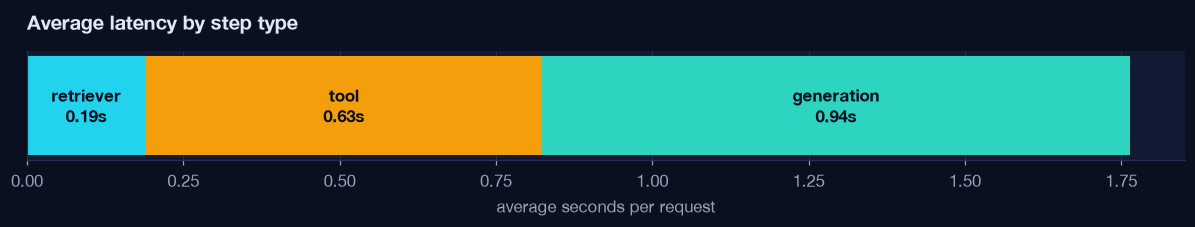

In [3]:
import matplotlib.pyplot as plt

children = obs[obs["type"].isin(["retriever", "tool", "generation"])]
breakdown = children.groupby(["traceId", "type"])["latency"].sum().unstack(fill_value=0)
breakdown = breakdown.loc[breakdown.index.isin(requests_df[~requests_df["failed"]].index)]
share = breakdown.mean()

fig, ax = plt.subplots(figsize=(11, 2.2))
left = 0
for kind in ["retriever", "tool", "generation"]:
    ax.barh(0, share[kind], left=left, color=lab.KIND_COLORS[kind], height=0.6)
    ax.text(left + share[kind] / 2, 0, f"{kind}\n{share[kind]:.2f}s", ha="center", va="center", color="#0B1020", fontweight="bold")
    left += share[kind]
ax.set_yticks([])
ax.set_xlabel("average seconds per request")
ax.set_title("Average latency by step type")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 4. The tail: p50 vs p95

Averages hide pain. The weather API is usually fast but sometimes takes 1.4 s and sometimes retries; that shows up only in the high percentiles.

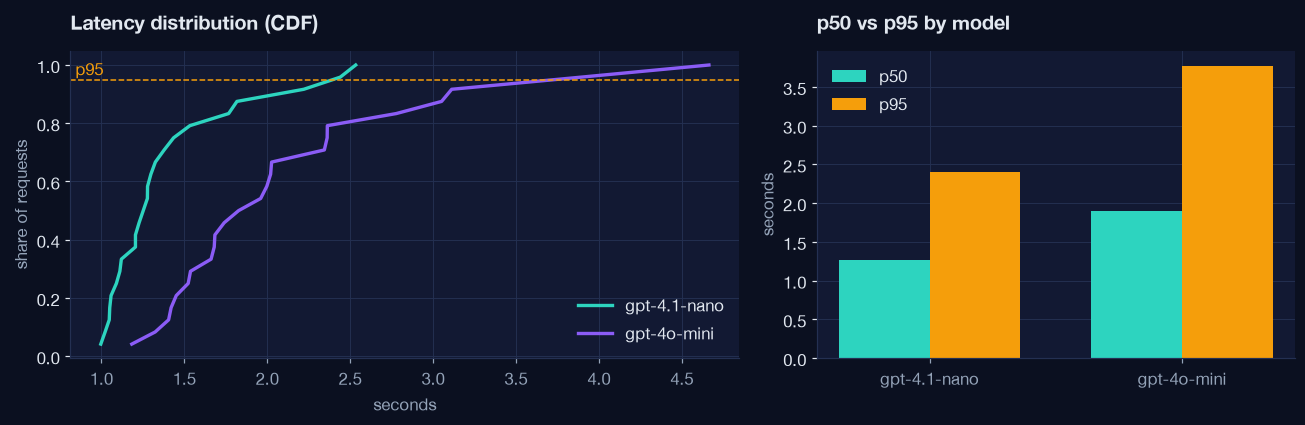

,p50,p95
model,,
gpt-4.1-nano,1.26s,2.41s
gpt-4o-mini,1.89s,3.77s


In [4]:
import numpy as np

ok = requests_df[~requests_df["failed"]]
pct = ok.groupby("model")["latency"].quantile([0.5, 0.95]).unstack()
pct.columns = ["p50", "p95"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1.4, 1]})
for i, (model, group) in enumerate(ok.groupby("model")):
    xs = np.sort(group["latency"].values)
    axes[0].plot(xs, np.arange(1, len(xs) + 1) / len(xs), linewidth=2.2, label=model, color=lab.SERIES[i])
axes[0].axhline(0.95, color="#F59E0B", linestyle="--", linewidth=1)
axes[0].text(axes[0].get_xlim()[0], 0.965, " p95", color="#F59E0B")
axes[0].set_title("Latency distribution (CDF)")
axes[0].set_xlabel("seconds")
axes[0].set_ylabel("share of requests")
axes[0].legend(frameon=False, labelcolor="#E2E8F0")

x = np.arange(len(pct))
axes[1].bar(x - 0.18, pct["p50"], 0.36, label="p50", color="#2DD4BF")
axes[1].bar(x + 0.18, pct["p95"], 0.36, label="p95", color="#F59E0B")
axes[1].set_xticks(x, pct.index)
axes[1].set_title("p50 vs p95 by model")
axes[1].set_ylabel("seconds")
axes[1].legend(frameon=False, labelcolor="#E2E8F0")
plt.tight_layout()
plt.show()
pct.style.format("{:.2f}s")

## 5. What does a request cost?

Langfuse computed cost per generation from the token counts and its model price table. Grouping by model and prompt version shows the effect of each choice.

In [5]:
cost = (
    requests_df.dropna(subset=["cost"])
    .groupby(["model", "prompt"])
    .agg(
        requests=("cost", "size"),
        avg_output_tokens=("output_tokens", "mean"),
        avg_cost=("cost", "mean"),
        p95_latency=("latency", lambda s: s.quantile(0.95)),
    )
)
cost["monthly_at_10k_per_day"] = cost["avg_cost"] * 10_000 * 30
cost.style.format(
    {"avg_output_tokens": "{:.0f}", "avg_cost": "${:.6f}", "p95_latency": "{:.2f}s", "monthly_at_10k_per_day": "${:,.2f}"}
)

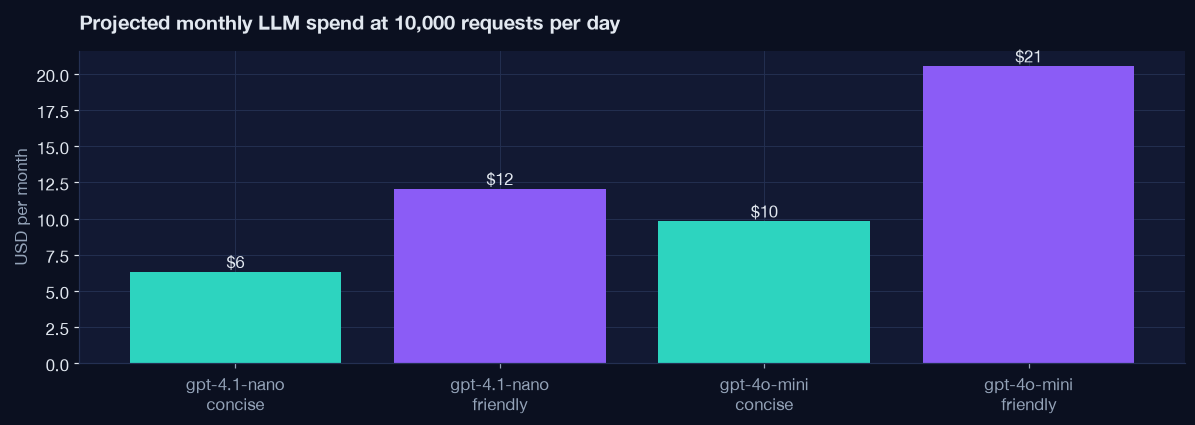

In [6]:
fig, ax = plt.subplots(figsize=(11, 4))
labels = [f"{m}\n{p}" for m, p in cost.index]
bars = ax.bar(labels, cost["monthly_at_10k_per_day"], color=[lab.SERIES[i % 2] for i in range(len(cost))])
for bar, value in zip(bars, cost["monthly_at_10k_per_day"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"${value:,.0f}", ha="center", va="bottom", color="#E2E8F0")
ax.set_title("Projected monthly LLM spend at 10,000 requests per day")
ax.set_ylabel("USD per month")
plt.tight_layout()
plt.show()

Read the table, not just the chart: the **friendly** prompt produces more output tokens, and output tokens are priced several times higher than input tokens. A one-line prompt change can multiply the bill, which is exactly why prompt version belongs on every trace.

## 6. Comparing prompt versions

Cost and latency are only half of the story; the other half is quality. We reuse the LLM-as-a-judge idea from notebook 03 on a sample of answers from each version and store the verdicts as scores.

In [7]:
import json

from openai import OpenAI as PlainOpenAI

judge_client = PlainOpenAI()  # not traced: the judge is our measuring tool here


def judge(question: str, answer: str) -> float:
    r = judge_client.chat.completions.create(
        model="gpt-4o-mini",
        response_format={"type": "json_object"},
        messages=[
            {"role": "system", "content": "Score the answer for being correct, direct and brief. JSON: {\"score\": 0..1}"},
            {"role": "user", "content": f"Question: {question}\nAnswer: {answer}"},
        ],
        max_tokens=20,
    )
    return float(json.loads(r.choices[0].message.content)["score"])


outputs = lab.langfuse_observations(limit=1000, userId=RUN, type="GENERATION", fields="core,io")
outputs["prompt"] = outputs["traceId"].map(roots["prompt"])
sample = outputs.dropna(subset=["prompt"]).groupby("prompt").head(6)

rows = []
for row in sample.itertuples():
    score = judge("Do I need an umbrella or a jacket?", row.output_text)
    langfuse.create_score(trace_id=row.traceId, name="quality", value=score, comment=f"prompt={row.prompt}")
    rows.append({"prompt": row.prompt, "quality": score})
langfuse.flush()

quality = pd.DataFrame(rows).groupby("prompt")["quality"].mean()
tokens = requests_df.groupby("prompt")["output_tokens"].mean()
pd.DataFrame({"avg quality (0..1)": quality, "avg output tokens": tokens}).style.format("{:.2f}")

,avg quality (0..1),avg output tokens
prompt,,
concise,1.00,29.67
friendly,0.80,82.88


This is the shape of every prompt decision: **quality vs cost vs latency**, measured, not guessed. In production you would run this on a fixed dataset (Langfuse and LangSmith both call this an *experiment*) before shipping a new version.

## 7. Should anyone be paged?

Dashboards are for humans; alerts are for thresholds. Define service level objectives and check them against the same data. Langfuse, LangSmith and Datadog can all run this kind of rule continuously.

In [8]:
error_rate = requests_df["failed"].mean()
p95 = ok["latency"].quantile(0.95)
avg_cost = requests_df["cost"].mean()

slos = [
    ("p95 latency", p95, 2.0, "{:.2f}s"),  # a tight objective for a chat UI
    ("error rate", error_rate, 0.05, "{:.1%}"),
    ("cost per request", avg_cost, 0.0002, "${:.6f}"),
]
for name, value, limit, fmt in slos:
    healthy = value <= limit
    lab.callout(
        f"{'OK' if healthy else 'ALERT'}  {name}",
        f"observed {fmt.format(value)} vs objective {fmt.format(limit)}",
        tone="teal" if healthy else "rose",
    )

## What to put on your first dashboard

| Panel | Metric | Why |
|---|---|---|
| Traffic | requests per minute, by route or agent | Context for every other number |
| Latency | p50 and p95 end to end, plus time to first token for streaming | What users feel |
| Errors | error rate by step type: tool, LLM, parse | Where to look first |
| Tokens | input and output tokens per request | Early warning for prompt bloat and loops |
| Cost | cost per request and per day, by model and feature | Budget, and the business case for optimizations |
| Quality | score averages by prompt version, user feedback rate | Catches silent failures |

Next: [06 Enterprise backends](06_enterprise_backends.ipynb) routes the same telemetry through an OpenTelemetry Collector toward Datadog and Dynatrace.